In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

In [2]:
df = pd.read_csv("global_pharmacy_sales_2020_2025_daily_dataset.csv")

print(df.head())
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns)

print("\nMissing values:")
print(df.isnull().sum())

         date  year  month  day         region    country category  \
0  2025-10-12  2025     10   12    Middle East        UAE  Chronic   
1  2020-09-15  2020      9   15     South Asia      India  Chronic   
2  2020-02-26  2020      2   26    Middle East        UAE  Vitamin   
3  2025-11-09  2025     11    9     South Asia  Sri Lanka  Chronic   
4  2022-04-04  2022      4    4  South America  Argentina  Chronic   

     medicine age_group  units_sold  unit_price  stock_level  \
0  Amlodipine      0-12         328       45.38         4774   
1  Amlodipine     26-45         371       75.49         4584   
2   Vitamin C      0-12         948       22.51         3934   
3  Amlodipine      0-12         275       63.29         4544   
4  Amlodipine     26-45         563       44.28         4284   

   expiry_days_remaining  covid_flag  
0                    466           0  
1                    181           1  
2                    556           1  
3                    330           0  

In [3]:
median_sales = df["units_sold"].median()

df["sales_class"] = np.where(
    df["units_sold"] > median_sales,
    "High Sales",
    "Low Sales"
)

print("Median units sold:", median_sales)
print(df["sales_class"].value_counts())

Median units sold: 387.0
sales_class
Low Sales     89124
High Sales    88866
Name: count, dtype: int64


In [4]:
#Select features and split the dataset
X = df.drop(
    columns=["units_sold", "sales_class", "date"]
)

y = df["sales_class"]

categorical_cols = X.select_dtypes(
    include=["object"]
).columns.tolist()

numerical_cols = X.select_dtypes(
    include=["number"]
).columns.tolist()

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (142392, 12)
Testing data: (35598, 12)


In [5]:
#Encode categorical features
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_cols
        ),
        (
            "numerical",
            "passthrough",
            numerical_cols
        )
    ]
)

In [6]:
#Train the basic Decision Tree Classifier
model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(random_state=42))
])

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Decision Tree Accuracy:",
      accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Decision Tree Accuracy: 0.8075172762514748

Classification Report:
              precision    recall  f1-score   support

  High Sales       0.81      0.81      0.81     17773
   Low Sales       0.81      0.80      0.81     17825

    accuracy                           0.81     35598
   macro avg       0.81      0.81      0.81     35598
weighted avg       0.81      0.81      0.81     35598



In [7]:
#Hyperparameter tuning using GridSearchCV
param_grid = {
    "classifier__criterion": ["gini", "entropy"],
    "classifier__max_depth": [3, 5, 8, 12, None],
    "classifier__min_samples_split": [2, 10, 20],
    "classifier__min_samples_leaf": [1, 5, 10],
    "classifier__ccp_alpha": [0.0, 0.001, 0.01]
}

grid_search = GridSearchCV(
    estimator=model,
    param_grid=param_grid,
    cv=3,
    scoring="f1_macro",
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

best_model = grid_search.best_estimator_

print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation F1 Score:")
print(grid_search.best_score_)

Fitting 3 folds for each of 270 candidates, totalling 810 fits
Best Parameters:
{'classifier__ccp_alpha': 0.0, 'classifier__criterion': 'entropy', 'classifier__max_depth': 8, 'classifier__min_samples_leaf': 10, 'classifier__min_samples_split': 2}

Best Cross-Validation F1 Score:
0.8483912731197857


Test Accuracy: 0.8510309567953256

Classification Report:
              precision    recall  f1-score   support

  High Sales       0.85      0.85      0.85     17773
   Low Sales       0.85      0.85      0.85     17825

    accuracy                           0.85     35598
   macro avg       0.85      0.85      0.85     35598
weighted avg       0.85      0.85      0.85     35598



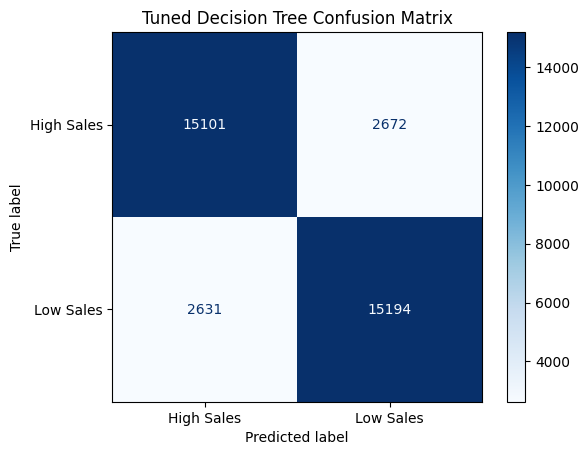

In [8]:
#Evaluate the tuned model
y_pred = best_model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print("Test Accuracy:", accuracy)

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=best_model.classes_
)

display_cm = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=best_model.classes_
)

display_cm.plot(cmap="Blues")
plt.title("Tuned Decision Tree Confusion Matrix")
plt.show()

ccp_alpha: 0.0 | Validation accuracy: 0.8480985989676604
ccp_alpha: 0.0001 | Validation accuracy: 0.8483092805224902
ccp_alpha: 0.001 | Validation accuracy: 0.8442009902033077
ccp_alpha: 0.005 | Validation accuracy: 0.836440886267074
ccp_alpha: 0.01 | Validation accuracy: 0.8195512482882124
ccp_alpha: 0.02 | Validation accuracy: 0.8195512482882124


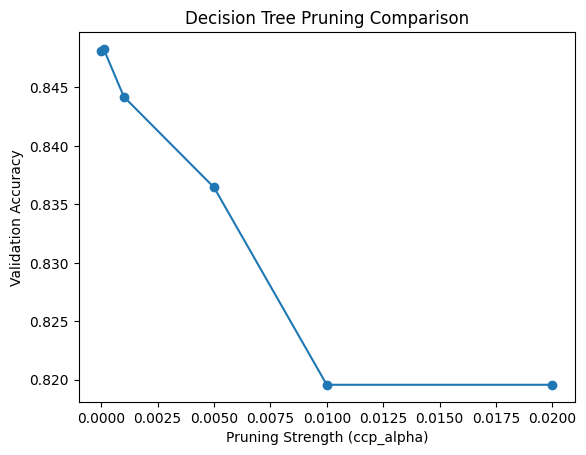

In [9]:
#Visualize the pruning strategy
X_train2, X_val, y_train2, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

alphas = [0.0, 0.0001, 0.001, 0.005, 0.01, 0.02]
val_scores = []

for alpha in alphas:
    prune_model = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", DecisionTreeClassifier(
            random_state=42,
            max_depth=grid_search.best_params_["classifier__max_depth"],
            min_samples_split=grid_search.best_params_[
                "classifier__min_samples_split"
            ],
            min_samples_leaf=grid_search.best_params_[
                "classifier__min_samples_leaf"
            ],
            criterion=grid_search.best_params_["classifier__criterion"],
            ccp_alpha=alpha
        ))
    ])

    prune_model.fit(X_train2, y_train2)

    val_pred = prune_model.predict(X_val)
    score = accuracy_score(y_val, val_pred)

    val_scores.append(score)

    print("ccp_alpha:", alpha, "| Validation accuracy:", score)

plt.plot(alphas, val_scores, marker="o")
plt.xlabel("Pruning Strength (ccp_alpha)")
plt.ylabel("Validation Accuracy")
plt.title("Decision Tree Pruning Comparison")
plt.show()

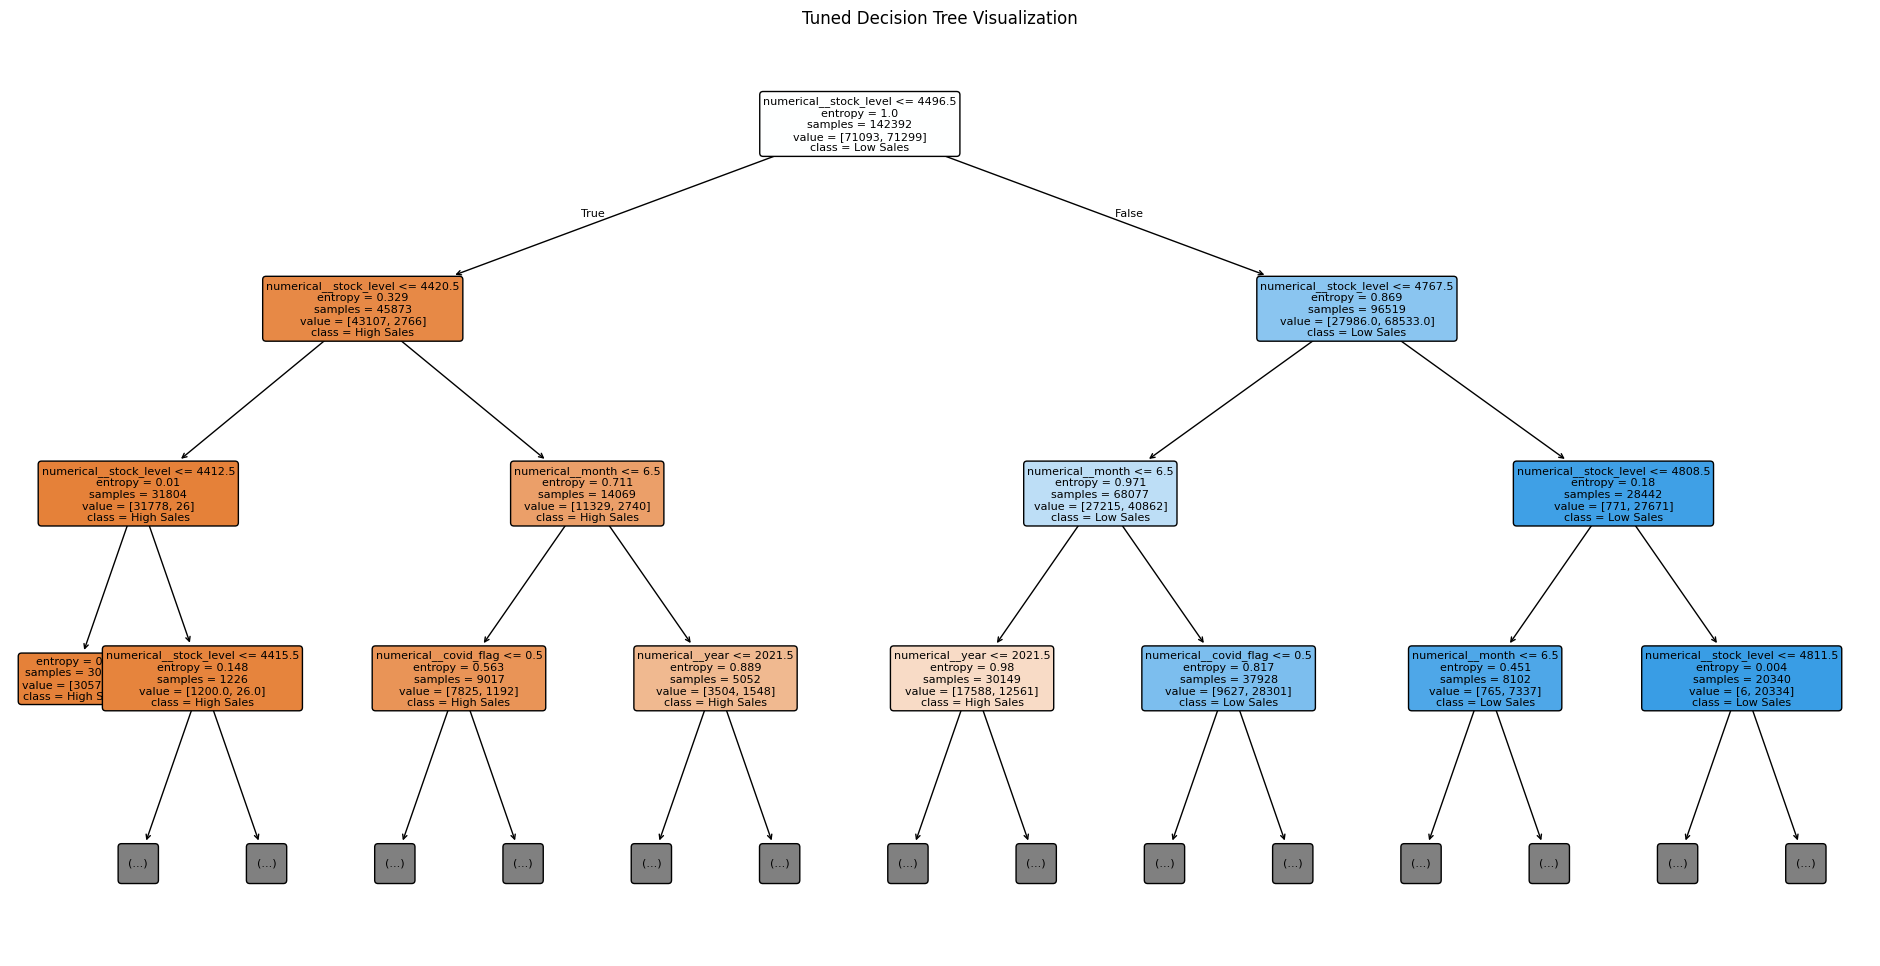

In [10]:
#Visualize the decision tree
preprocessor_fitted = best_model.named_steps["preprocessor"]
tree_model = best_model.named_steps["classifier"]

feature_names = preprocessor_fitted.get_feature_names_out()

plt.figure(figsize=(24, 12))

plot_tree(
    tree_model,
    feature_names=feature_names,
    class_names=tree_model.classes_,
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=8
)

plt.title("Tuned Decision Tree Visualization")
plt.show()

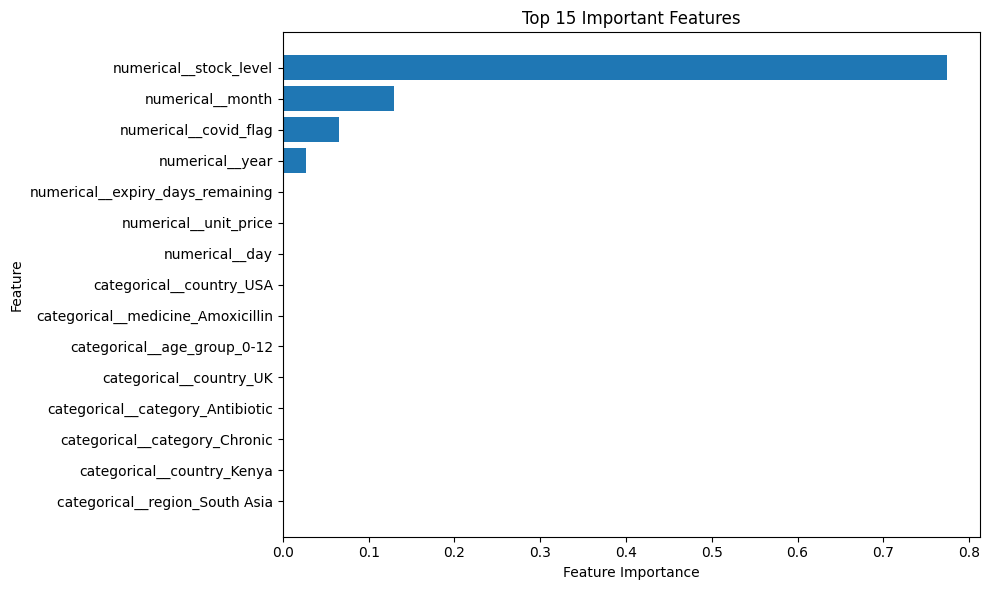

                              Feature  Importance
51             numerical__stock_level    0.774014
48                   numerical__month    0.130029
53              numerical__covid_flag    0.065037
47                    numerical__year    0.026748
52   numerical__expiry_days_remaining    0.001001
50              numerical__unit_price    0.000772
49                     numerical__day    0.000536
26           categorical__country_USA    0.000189
33  categorical__medicine_Amoxicillin    0.000151
42        categorical__age_group_0-12    0.000151
25            categorical__country_UK    0.000128
27   categorical__category_Antibiotic    0.000120
29      categorical__category_Chronic    0.000111
18         categorical__country_Kenya    0.000077
7      categorical__region_South Asia    0.000073


In [11]:
#Feature importance visualization
importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": tree_model.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
).head(15)

plt.figure(figsize=(10, 6))

plt.barh(
    importance["Feature"][::-1],
    importance["Importance"][::-1]
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Top 15 Important Features")
plt.tight_layout()
plt.show()

print(importance)

In [12]:
#Interpret an individual decision path
sample = X_test.iloc[[0]]

sample_transformed = preprocessor_fitted.transform(sample)

decision_path = tree_model.decision_path(sample_transformed)
leaf_id = tree_model.apply(sample_transformed)[0]

node_indices = decision_path.indices[
    decision_path.indptr[0]:decision_path.indptr[1]
]

print("Actual class:", y_test.iloc[0])
print("Predicted class:", best_model.predict(sample)[0])
print("\nDecision path:")

for node_id in node_indices:
    if node_id == leaf_id:
        print("Reached leaf node:", node_id)
        continue

    feature_index = tree_model.tree_.feature[node_id]
    threshold = tree_model.tree_.threshold[node_id]

    print(
        f"Node {node_id}: "
        f"{feature_names[feature_index]} <= {threshold:.3f}"
    )

Actual class: Low Sales
Predicted class: High Sales

Decision path:
Node 0: numerical__stock_level <= 4496.500
Node 138: numerical__stock_level <= 4767.500
Node 139: numerical__month <= 6.500
Node 140: numerical__year <= 2021.500
Node 170: numerical__stock_level <= 4665.500
Node 171: numerical__month <= 5.500
Node 172: numerical__stock_level <= 4560.500
Node 176: numerical__stock_level <= 4627.500
Reached leaf node: 178


In [13]:
#Display the final model summary
print("Final Model: Decision Tree Classifier")
print("Best Parameters:", grid_search.best_params_)
print("Test Accuracy:", accuracy_score(y_test, best_model.predict(X_test)))
print("Tree Depth:", tree_model.get_depth())
print("Number of Leaves:", tree_model.get_n_leaves())

Final Model: Decision Tree Classifier
Best Parameters: {'classifier__ccp_alpha': 0.0, 'classifier__criterion': 'entropy', 'classifier__max_depth': 8, 'classifier__min_samples_leaf': 10, 'classifier__min_samples_split': 2}
Test Accuracy: 0.8510309567953256
Tree Depth: 8
Number of Leaves: 169
